In [13]:
# DATA MINING 1
# CLUSTERING

In [14]:
# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE

# Base
import math
import os
from math import sqrt

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)

'''# Pattern Mining
from fim import (
    fpgrowth,
    apriori,
)'''

# Xmeans
from pyclustering.cluster import xmeans

os.environ['LOKY_MAX_CPU_COUNT'] = '12'

In [15]:
# CARICAMENTO DATAFRAME

# Base e Cleaned
df = pd.read_csv("DM1_game_dataset.csv")
df_cleaned = pd.read_csv("df_cleaned.csv")

# Train & Test
train_set = pd.read_csv("train_set.csv")
test_set = pd.read_csv("test_set.csv")

# Imputed
train_imputed = pd.read_csv("train_imputed.csv")
test_imputed = pd.read_csv("test_imputed.csv")

# Transformed
train_transformed = pd.read_csv("train_transformed.csv")
test_transformed = pd.read_csv("test_transformed.csv")

In [16]:
# Identificazione Colonne

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]
# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation", "RatingBinaria"]

# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist()
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))

In [17]:
# Misc

# Stile Grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# Scalers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Numerosità
n_train = len(train_set["Rating"])
n_test = len(test_set["Rating"])

In [18]:
# -----------------------------------------------
# -----------------------------------------------

# CLUSTERING

In [19]:
# Creazione Datasets

train_cluster = train_imputed.copy()
test_cluster = test_imputed.copy()
colonne_cluster = ["MediaPlaytime", "GameWeight", "ComAgeRec", "MinPlayers",
                   "Age"]
train_cluster = train_cluster[colonne_cluster]
test_cluster = test_cluster[colonne_cluster]
X = train_cluster
y = np.array(train_imputed['Rating'])

X_minmax = minmax_scaler.fit_transform(X)
X_standard = standard_scaler.fit_transform(X)

In [20]:
# PCA
features = train_cluster.select_dtypes(include=[np.number])
features_scaled = minmax_scaler.fit_transform(features)
pca = PCA(n_components=5, random_state=222)
principal_components = pca.fit_transform(features_scaled)
pca_df = pd.DataFrame(data=principal_components,
                      columns=['PC1', 'PC2', "PC3", "PC4", "PC5"])

explained_variance = pca.explained_variance_ratio_
total_explained_variance = np.sum(explained_variance)

print("\n--- Varianza Spiegata ---")
print(
    f"Varianza spiegata da PC1: {explained_variance[0]:.4f} ({explained_variance[0] * 100:.2f}%)")
print(
    f"Varianza spiegata da PC2: {explained_variance[1]:.4f} ({explained_variance[1] * 100:.2f}%)")
print(
    f"Varianza spiegata da PC3: {explained_variance[2]:.4f} ({explained_variance[2] * 100:.2f}%)")
print(
    f"Varianza spiegata da PC4: {explained_variance[3]:.4f} ({explained_variance[3] * 100:.2f}%)")
print(
    f"Varianza spiegata da PC5: {explained_variance[4]:.4f} ({explained_variance[4] * 100:.2f}%)")

print(
    f"Varianza Totale Spiegata (5 componenti): {total_explained_variance:.4f} ({total_explained_variance * 100:.2f}%)")


--- Varianza Spiegata ---
Varianza spiegata da PC1: 0.7412 (74.12%)
Varianza spiegata da PC2: 0.1295 (12.95%)
Varianza spiegata da PC3: 0.0867 (8.67%)
Varianza spiegata da PC4: 0.0403 (4.03%)
Varianza spiegata da PC5: 0.0023 (0.23%)
Varianza Totale Spiegata (5 componenti): 1.0000 (100.00%)


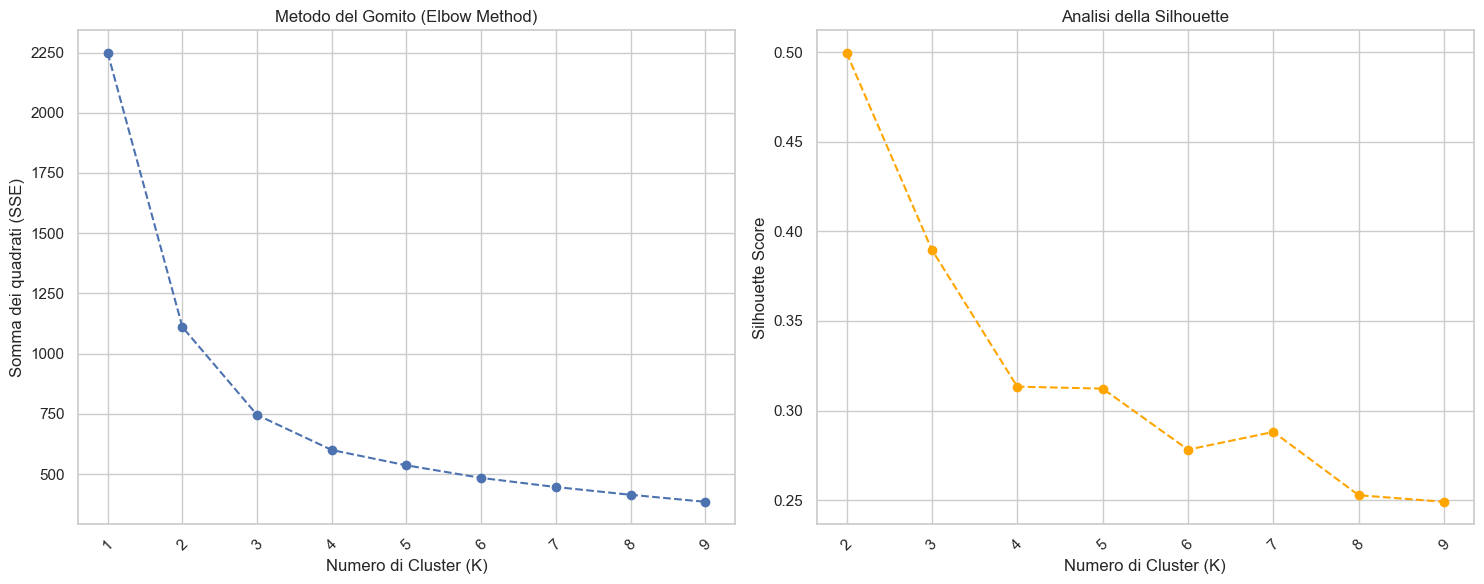

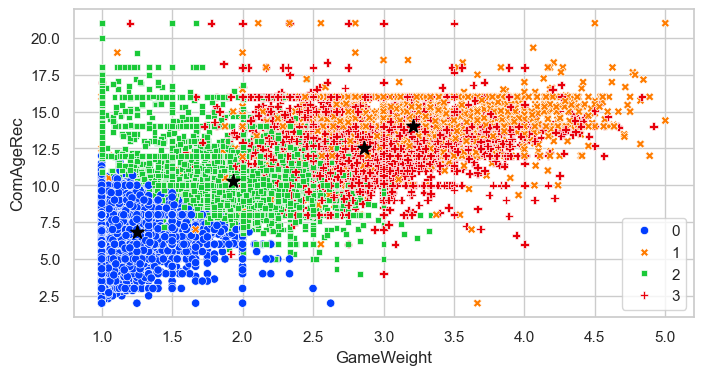

In [21]:
# K_Means
sse = []
silhouette_scores = []
k_range = range(1, 10)

for k in k_range:
    kmeans_model = KMeans(n_clusters=k,
                          n_init=10,
                          max_iter=10,
                          random_state=222)

    kmeans_model.fit(X_minmax)

    if k > 1:
        score = silhouette_score(X_minmax, kmeans_model.labels_)
        silhouette_scores.append(score)

    sse.append(kmeans_model.inertia_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.plot(k_range, sse, marker='o', linestyle='--')
ax1.set_xlabel("Numero di Cluster (K)")
ax1.set_ylabel("Somma dei quadrati (SSE)")
ax1.set_title("Metodo del Gomito (Elbow Method)")
ax1.set_xticks(k_range)
ax1.tick_params(axis='x', labelrotation=45)
ax1.grid(True)

ax2.plot(k_range[1:], silhouette_scores,
         marker='o', linestyle='--', color='orange')
ax2.set_xlabel("Numero di Cluster (K)")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Analisi della Silhouette")
ax2.set_xticks(k_range[1:])
ax2.tick_params(axis='x', labelrotation=45)
ax2.grid(True)

plt.tight_layout()
plt.show()

# Modello effettivo
kmeans = KMeans(n_clusters=4, n_init=10, max_iter=10, random_state=222)
kmeans.fit(X_minmax)

centers = kmeans.cluster_centers_
centers_unscaled = minmax_scaler.inverse_transform(centers)

sns.scatterplot(data=train_cluster,
                x="GameWeight",
                y="ComAgeRec",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")
plt.scatter(
    centers_unscaled[:, 1],
    centers_unscaled[:, 2],
    color="black", marker="*", s=100
)
plt.show()

In [22]:
train_cluster['Cluster_Label'] = kmeans.labels_
numerosita = train_cluster['Cluster_Label'].value_counts().sort_index()
print(numerosita)

# guarda i centri
# CLUSTER 0: Giochi mediamente lunghi, mediamente difficili per giocatori a partire da 12 anni

Cluster_Label
0    5555
1    1606
2    6411
3    3478
Name: count, dtype: int64


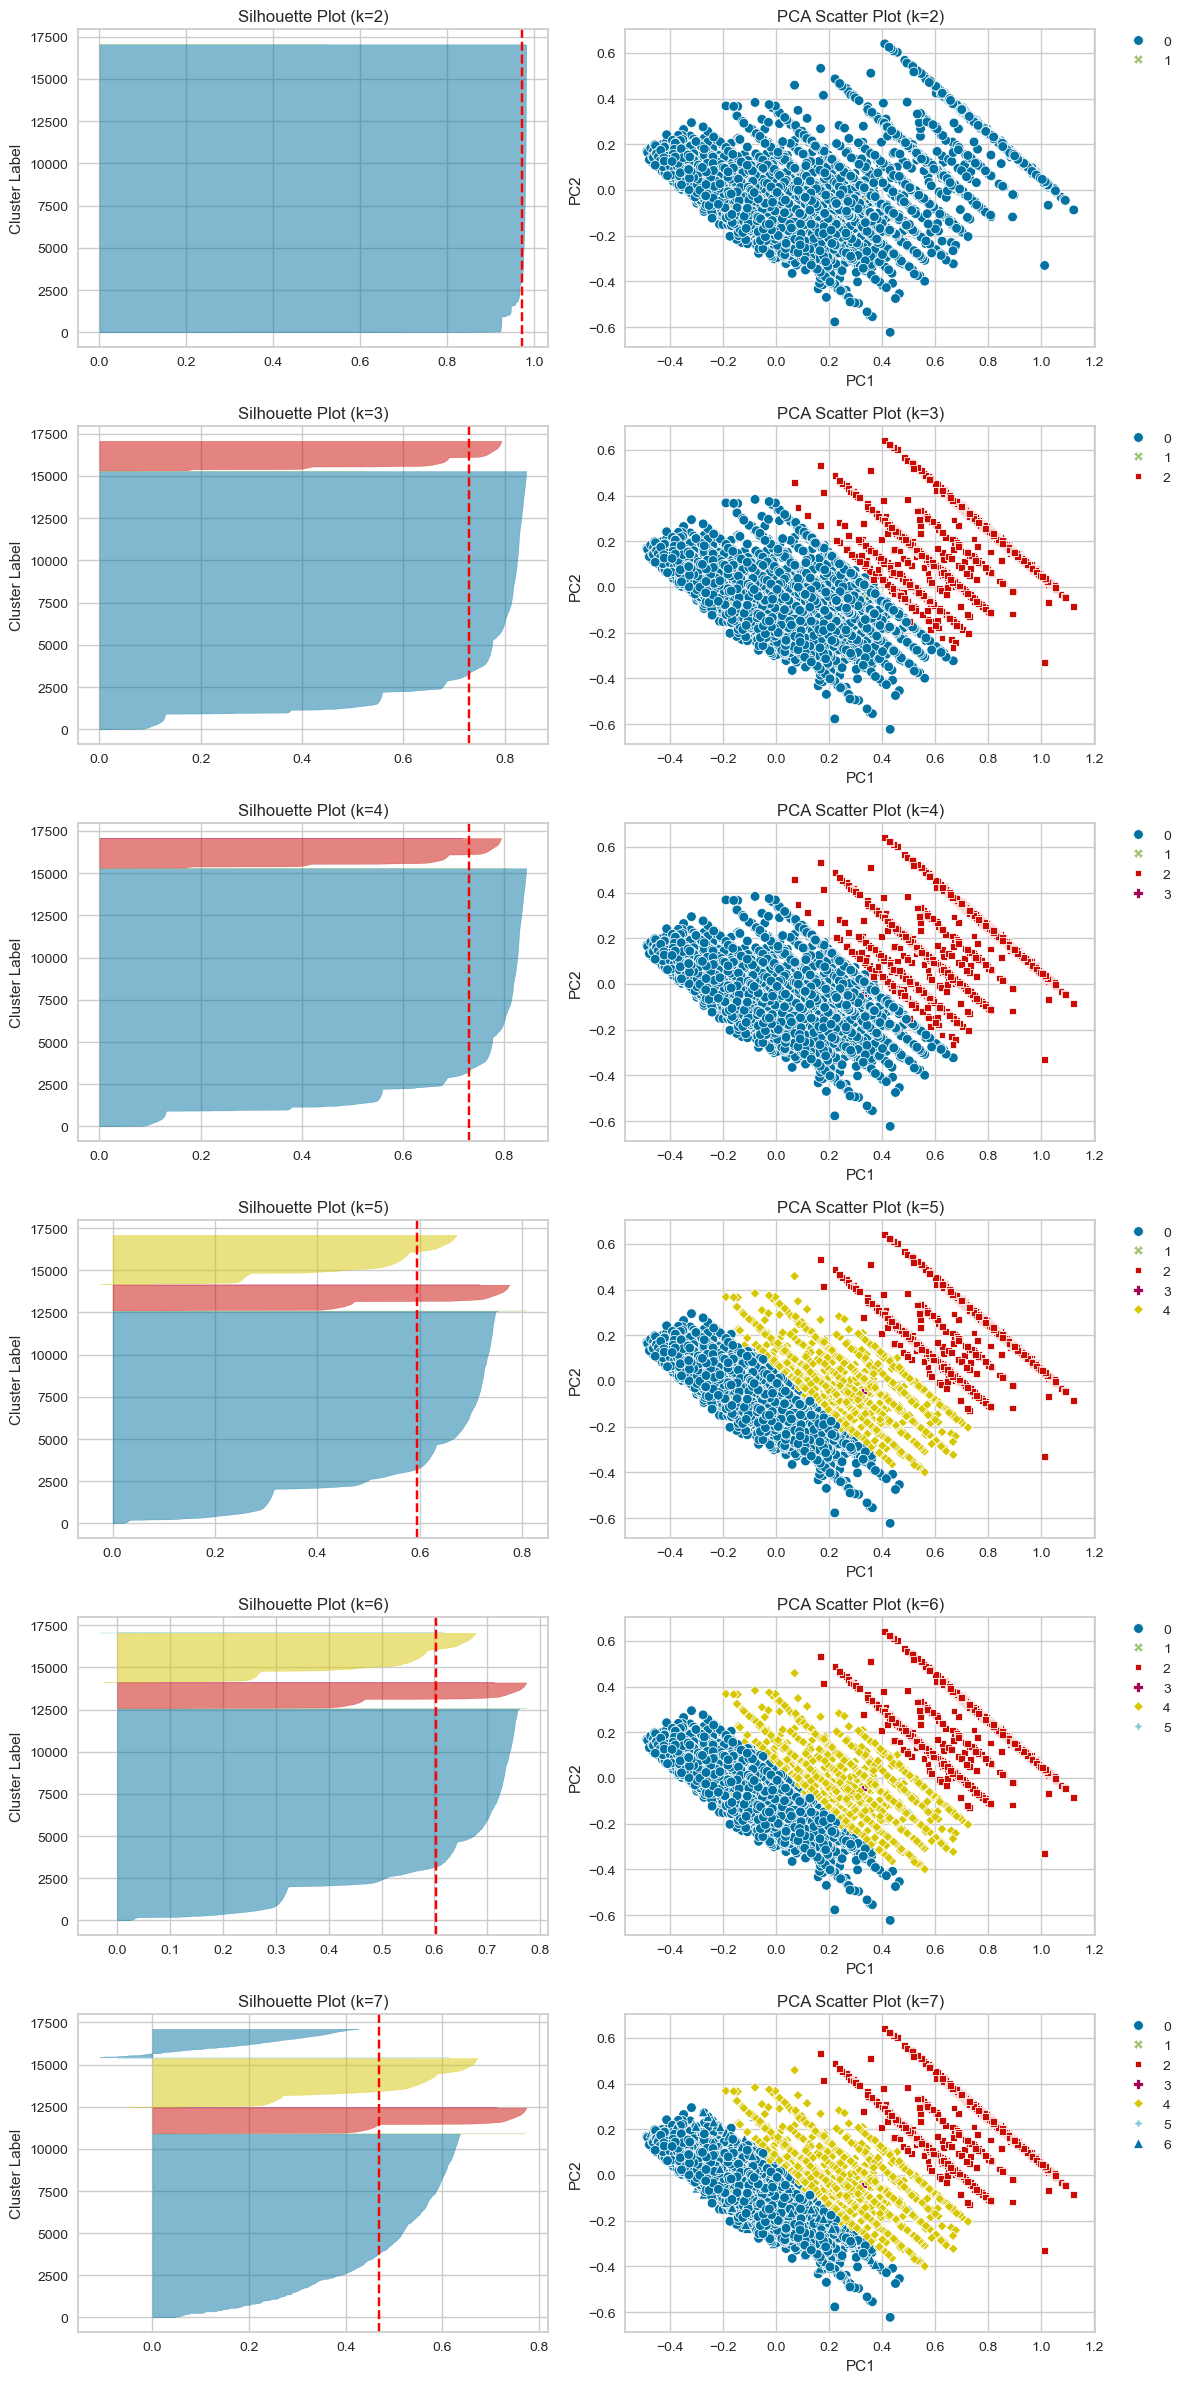

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from yellowbrick.cluster import SilhouetteVisualizer
from sklearn.cluster import BisectingKMeans

colors = ['C0', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7']
min_k = 2
max_k = 8  # n_clust nel tuo codice originale
n_rows = max_k - min_k


fig, axs = plt.subplots(n_rows, 2, figsize=(12, 4 * n_rows))

for i in range(min_k, max_k):
    idx = i - min_k
    kmeans = KMeans(n_clusters=i, random_state=42)

    visualizer = SilhouetteVisualizer(kmeans, colors=colors, ax=axs[idx][0])
    visualizer.fit(X)

    axs[idx][0].set_title(f"Silhouette Plot (k={i})")
    axs[idx][0].set_ylabel("Cluster Label")

    # --- 2. Scatter Plot PCA ---
    # Prediciamo le etichette per il plot
    labels = kmeans.labels_
    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue=labels,
        style=labels,
        palette=sns.color_palette(colors[:i]),
        ax=axs[idx][1],
        legend="full"
    )
    axs[idx][1].set_title(f"PCA Scatter Plot (k={i})")
    axs[idx][1].legend(bbox_to_anchor=(1.05, 1),
                       loc='upper left', borderaxespad=0.)

# Ottimizza lo spazio tra i grafici
plt.tight_layout()
plt.show()

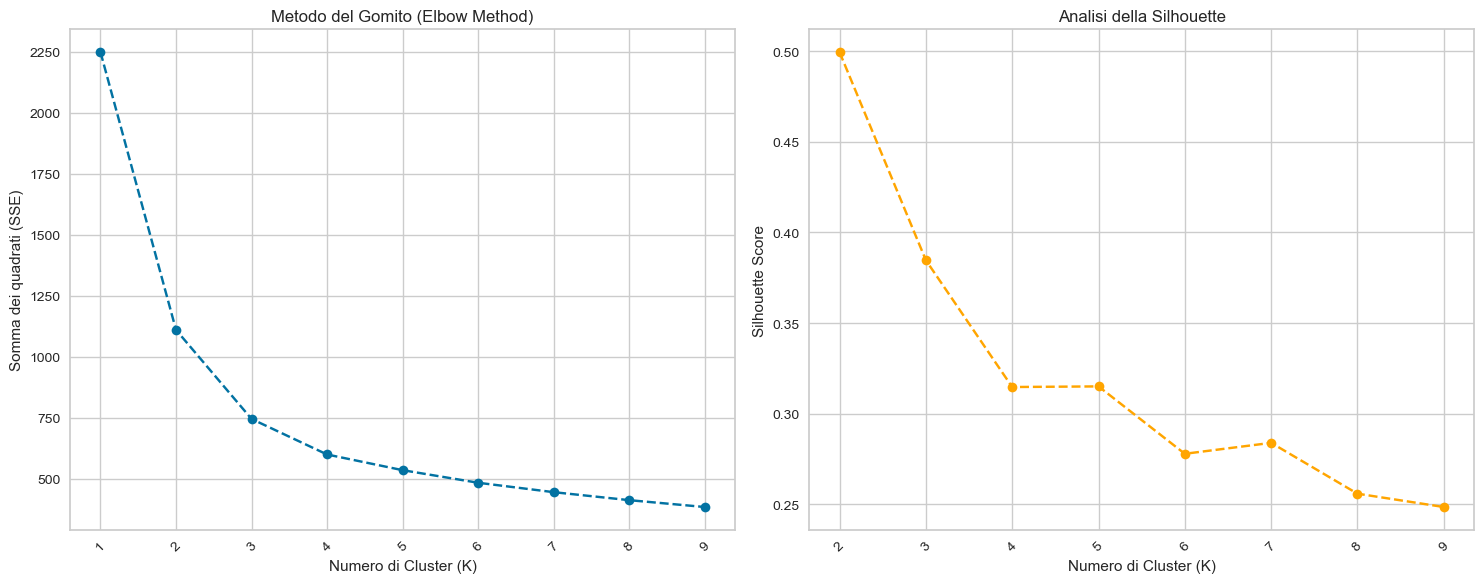

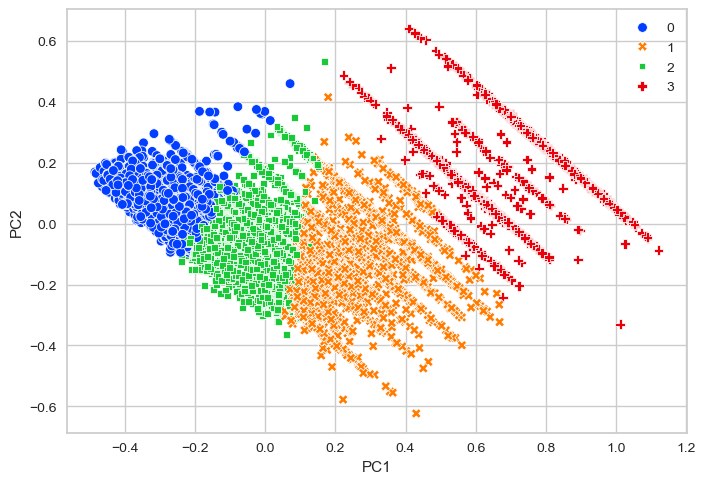

SSE 599.6268012427922


In [24]:
# K_Means
sse = []
silhouette_scores = []
k_range = range(1, 10)

for k in k_range:
    kmeans_model = KMeans(n_clusters=k,
                          n_init=10,
                          max_iter=40,
                          random_state=222)

    kmeans_model.fit(X_minmax)

    if k > 1:
        score = silhouette_score(X_minmax, kmeans_model.labels_)
        silhouette_scores.append(score)

    sse.append(kmeans_model.inertia_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.plot(k_range, sse, marker='o', linestyle='--')
ax1.set_xlabel("Numero di Cluster (K)")
ax1.set_ylabel("Somma dei quadrati (SSE)")
ax1.set_title("Metodo del Gomito (Elbow Method)")
ax1.set_xticks(k_range)
ax1.tick_params(axis='x', labelrotation=45)
ax1.grid(True)

ax2.plot(k_range[1:], silhouette_scores,
         marker='o', linestyle='--', color='orange')
ax2.set_xlabel("Numero di Cluster (K)")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Analisi della Silhouette")
ax2.set_xticks(k_range[1:])
ax2.tick_params(axis='x', labelrotation=45)
ax2.grid(True)

plt.tight_layout()
plt.show()

# Modello effettivo
kmeans = KMeans(n_clusters=4, n_init=10, max_iter=100, random_state=222)
kmeans.fit(X_minmax)

centers = kmeans.cluster_centers_
centers_unscaled = minmax_scaler.inverse_transform(centers)

sns.scatterplot(data=pca_df,
                x="PC1",
                y="PC2",
                hue=kmeans.labels_,
                style=kmeans.labels_,
                palette="bright")

plt.show()

print('SSE', kmeans.inertia_)

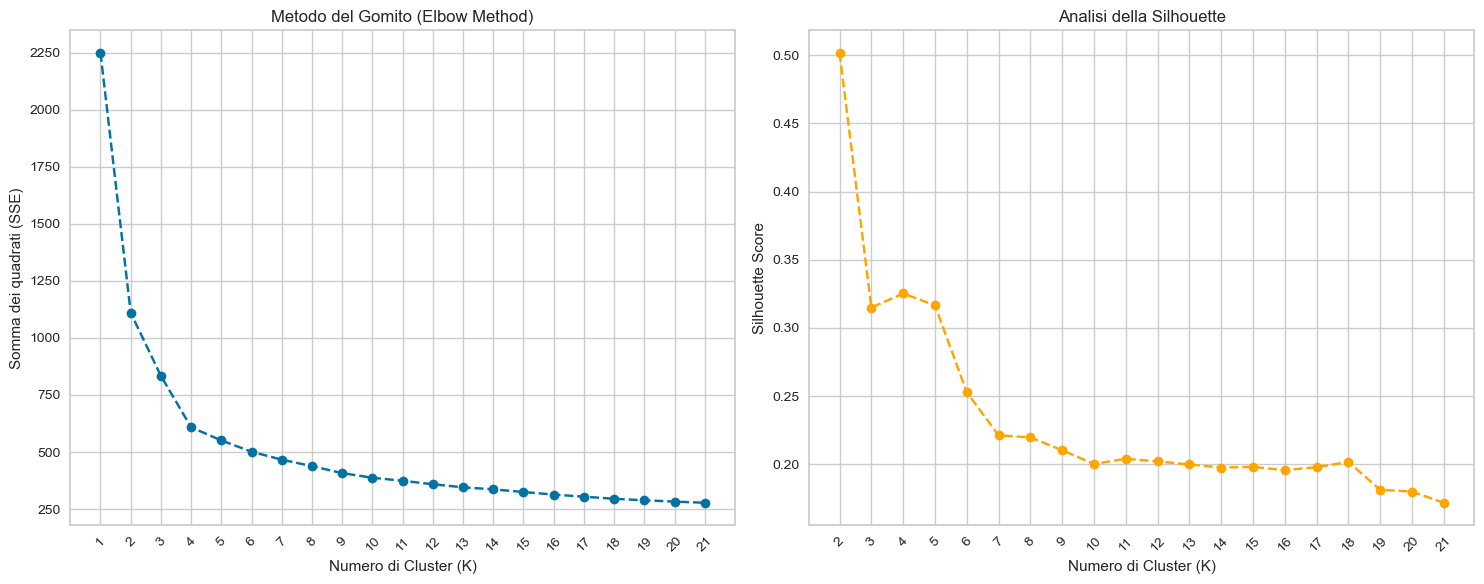

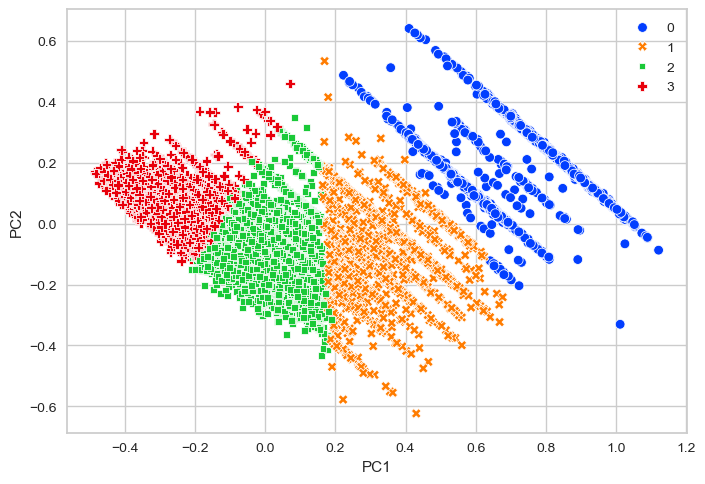

SSE 277.7710485308171


In [25]:
# Bisecting K_Means
sse = []
silhouette_scores = []
k_range = range(1, 22)

for k in k_range:
    bkmeans_model = BisectingKMeans(n_clusters=k,
                                    n_init=10,
                                    max_iter=100,
                                    random_state=222)

    bkmeans_model.fit(X_minmax)
    if k > 1:
        score = silhouette_score(X_minmax, bkmeans_model.labels_)
        silhouette_scores.append(score)

    sse.append(bkmeans_model.inertia_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.plot(k_range, sse, marker='o', linestyle='--')
ax1.set_xlabel("Numero di Cluster (K)")
ax1.set_ylabel("Somma dei quadrati (SSE)")
ax1.set_title("Metodo del Gomito (Elbow Method)")
ax1.set_xticks(k_range)
ax1.tick_params(axis='x', labelrotation=45)
ax1.grid(True)

ax2.plot(k_range[1:], silhouette_scores,
         marker='o', linestyle='--', color='orange')
ax2.set_xlabel("Numero di Cluster (K)")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Analisi della Silhouette")
ax2.set_xticks(k_range[1:])
ax2.tick_params(axis='x', labelrotation=45)
ax2.grid(True)

plt.tight_layout()
plt.show()

bkmeans = BisectingKMeans(n_clusters=4, n_init=10,
                          max_iter=100, random_state=222)
bkmeans.fit(X_minmax)

sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue=bkmeans.labels_,
                style=bkmeans.labels_, palette="bright")
plt.show()

print('SSE', bkmeans_model.inertia_)

In [26]:
from pyclustering.cluster.xmeans import xmeans
from pyclustering.cluster.center_initializer import kmeans_plusplus_initializer
from sklearn.metrics import silhouette_score
import numpy as np
import matplotlib.pyplot as plt

sse = []
silhouette_scores = []
k_range = range(2, 12)  # Analizziamo da 2 a 11 cluster
data_list = X_minmax.tolist()

for k in k_range:
    # 1. Inizializzazione centri (partiamo da k centri)
    initial_centers = kmeans_plusplus_initializer(data_list, k).initialize()

    # 2. Esecuzione X-Means
    # Usiamo kmax=20 come limite superiore per l'algoritmo
    xm_model = xmeans(data_list, initial_centers, kmax=20)
    xm_model.process()

    # 3. Estrazione Cluster e Centri
    clusters = xm_model.get_clusters()
    centers = xm_model.get_centers()

    # 4. Creazione array delle etichette (labels)
    labels = np.zeros(len(data_list), dtype=int)
    for cluster_id, idx_list in enumerate(clusters):
        for idx in idx_list:
            labels[idx] = cluster_id

    # 5. Calcolo manuale del SSE (Somma dei Quadrati degli Errori)
    current_sse = 0
    for cluster_id, idx_list in enumerate(clusters):
        center = np.array(centers[cluster_id])
        points = X_minmax[idx_list]
        # Distanza euclidea al quadrato: sum((punto - centro)^2)
        current_sse += np.sum(np.square(points - center))

    sse.append(current_sse)

    # 6. Calcolo Silhouette Score
    score = silhouette_score(X_minmax, labels)
    silhouette_scores.append(score)

# --- Generazione Grafici ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Grafico Elbow
ax1.plot(k_range, sse, marker='o', linestyle='--')
ax1.set_xlabel("Numero di Cluster (K)")
ax1.set_ylabel("Somma dei quadrati (SSE)")
ax1.set_title("Metodo del Gomito (X-Means)")
ax1.grid(True)

# Grafico Silhouette
ax2.plot(k_range, silhouette_scores, marker='o',
         linestyle='--', color='orange')
ax2.set_xlabel("Numero di Cluster (K)")
ax2.set_ylabel("Silhouette Score")
ax2.set_title("Analisi della Silhouette (X-Means)")
ax2.grid(True)

plt.tight_layout()
plt.show()
''

# 1. Preparazione dati: pyclustering richiede una lista di liste
# Usiamo X_minmax che hai già creato nel tuo codice
data_input = X_minmax.tolist()

# 2. Inizializzazione dei centri
# X-means parte da un numero K iniziale e cresce se necessario
amount_initial_centers = 2
initial_centers = kmeans_plusplus_initializer(
    data_input, amount_initial_centers).initialize()

# 3. Esecuzione X-Means
# kmax=10 evita che l'algoritmo crei troppi cluster frammentando i dati
xm_instance = xmeans(data_input, initial_centers, kmax=8)
xm_instance.process()

# 4. Estrazione dei risultati
# Lista di liste: [[indici_cluster_0], [indici_cluster_1], ...]
clusters = xm_instance.get_clusters()
centers = np.array(xm_instance.get_centers())

# 5. ASSOCIAZIONE CORRETTA DELLE ETICHETTE
# Creiamo un array di zero lungo quanto i nostri dati
labels_xmeans = np.zeros(len(data_input), dtype=int)

# Per ogni cluster trovato, assegniamo l'ID corretto agli indici corrispondenti
for cluster_id, idx_list in enumerate(clusters):
    for idx in idx_list:
        labels_xmeans[idx] = cluster_id

# 6. Visualizzazione
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue=labels_xmeans,
    style=labels_xmeans,
    palette="bright",
    legend="full"
)
plt.title(f"X-Means Clustering (Trovati {len(clusters)} cluster)")
plt.show()

AttributeError: module 'numpy' has no attribute 'warnings'

Epsilon calcolato automaticamente: 0.0860


C:\Users\Riccardo\AppData\Local\Temp\ipykernel_21056\1018043908.py:17: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  cross_product = np.cross(vec_line, coords - p1)


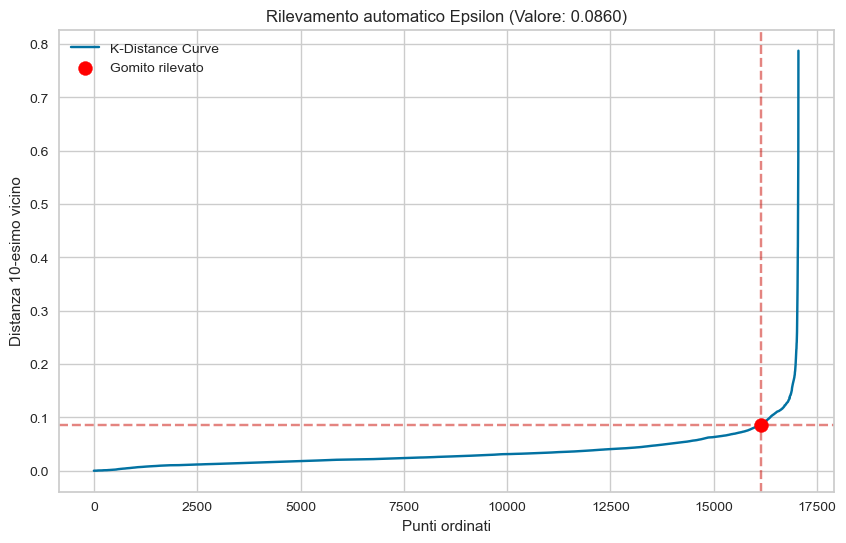

Cluster trovati: 24
Punti di rumore: 2079 (12.19%)


Cluster_Label
-1      2079
 0     10064
 1       578
 2      1821
 3      1524
 4       320
 5        14
 6       153
 7       134
 8        40
 9        19
 10       42
 11       91
 12       35
 13       34
 14        9
 15       10
 16       15
 17        8
 18        7
 19       13
 20       10
 21       12
 22       13
 23        5
Name: count, dtype: int64


In [27]:
# Dbscan

# --- FUNZIONE PER TROVARE IL GOMITO AUTOMATICAMENTE ---
def find_knee_point(sorted_values):
    x = np.arange(len(sorted_values))
    y = sorted_values

    # Normalizzazione
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())

    coords = np.vstack((x_norm, y_norm)).T
    p1 = coords[0]
    p2 = coords[-1]
    vec_line = p2 - p1

    cross_product = np.cross(vec_line, coords - p1)
    distances_to_line = np.abs(cross_product) / np.linalg.norm(vec_line)

    knee_idx = np.argmax(distances_to_line)
    return knee_idx, sorted_values[knee_idx]

# -------------------------------------------------------


# 1. Parametri base
D = X_minmax.shape[1]
MinPts = 2 * D
k = MinPts

# 2. Calcolo K-distanze
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_minmax)
distances, indices = nn.kneighbors(X_minmax)
k_distances = distances[:, k - 1]
k_distances_sorted = np.sort(k_distances)

# 3. Calcolo AUTOMATICO di Epsilon
knee_index, epsilon_auto = find_knee_point(k_distances_sorted)
print(f"Epsilon calcolato automaticamente: {epsilon_auto:.4f}")

# 4. Plot del grafico K-distance
plt.figure(figsize=(10, 6))
plt.plot(k_distances_sorted, label='K-Distance Curve')
plt.scatter(knee_index, epsilon_auto, color='red',
            s=100, label='Gomito rilevato', zorder=5)
plt.axhline(y=epsilon_auto, color='r', linestyle='--', alpha=0.5)
plt.axvline(x=knee_index, color='r', linestyle='--', alpha=0.5)

plt.title(f"Rilevamento automatico Epsilon (Valore: {epsilon_auto:.4f})")
plt.xlabel('Punti ordinati')
plt.ylabel(f"Distanza {k}-esimo vicino")
plt.legend()
plt.grid(True)
plt.show()

# 5. Esecuzione DBSCAN
dbscan = DBSCAN(eps=0.05, min_samples=MinPts)
dbscan.fit(X_minmax)

# 6. Preparazione Dati
plot_df = pca_df.copy()
plot_df['cluster'] = dbscan.labels_.astype(str)

# Statistiche
n_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
n_noise = list(dbscan.labels_).count(-1)
perc_noise = (n_noise / len(plot_df)) * 100

# Costruzione stringhe separate per evitare errori di formattazione
msg_clusters = f"Cluster trovati: {n_clusters}"
msg_noise = f"Punti di rumore: {n_noise} ({perc_noise:.2f}%)"
plot_title = f"DBSCAN Auto-Tuned (Eps={epsilon_auto:.3f}, MinPts={MinPts})"

print(msg_clusters)
print(msg_noise)

# 7. Plot 3D
# Ordiniamo i cluster per la legenda
sorted_clusters = sorted(plot_df['cluster'].unique())

fig = px.scatter_3d(
    plot_df,
    x='PC1', y='PC2', z='PC3',
    color='cluster',
    title=plot_title,
    color_discrete_map={'-1': 'darkgrey'},
    category_orders={"cluster": sorted_clusters}

)

fig.update_traces(marker=dict(size=3, opacity=0.7))
fig.show()


# 1. Ottieni le etichette (già fatto col tuo fit)
labels = dbscan.labels_

# 2. Crea i centroidi calcolando la media per ogni cluster (escluso il rumore -1)
centers1 = np.array([X_minmax[labels == i].mean(axis=0)
                    for i in set(labels) if i != -1])

# 3. Riporta i valori alla scala originale
if len(centers1) > 0:
    centers_unscaled1 = minmax_scaler.inverse_transform(centers1)
else:
    print("DBSCAN non ha trovato cluster (solo rumore).")


train_cluster['Cluster_Label'] = dbscan.labels_
numerosita = train_cluster['Cluster_Label'].value_counts().sort_index()
print(numerosita)

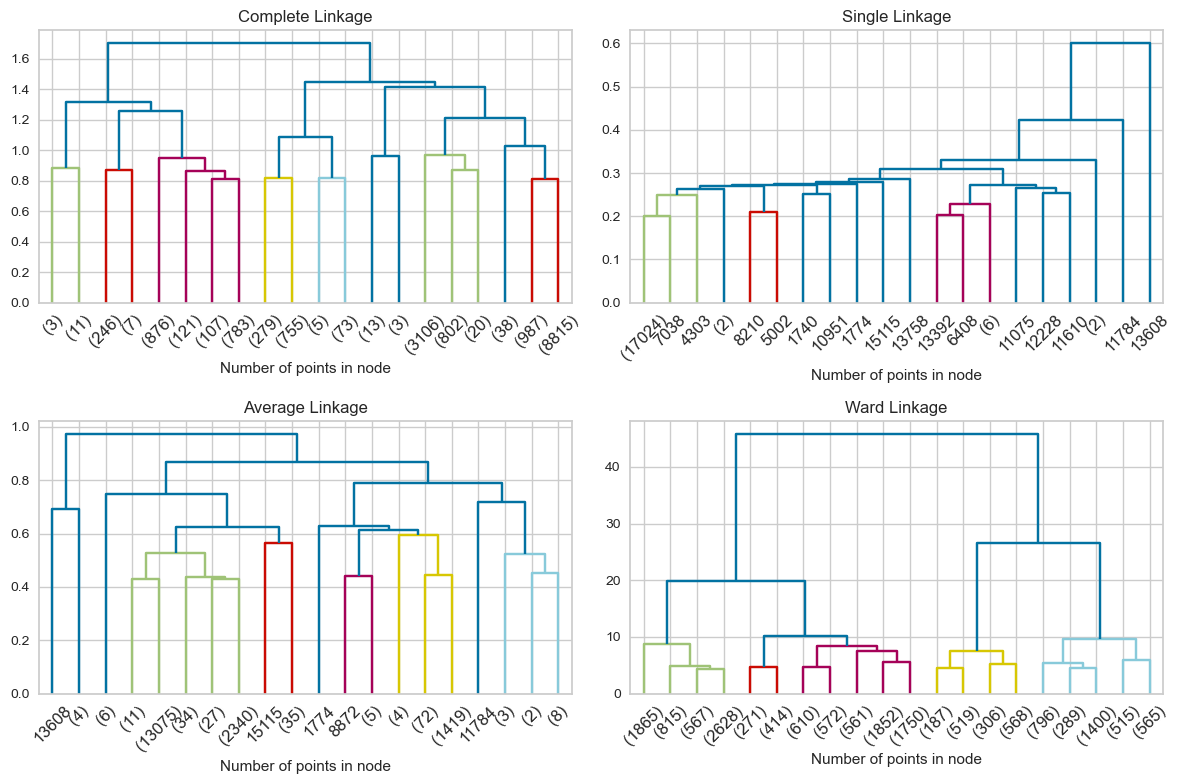

In [28]:
# Gerarchico

def get_linkage_matrix(model):
    # Create linkage matrix

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    return linkage_matrix


def plot_dendrogram(model, **kwargs):
    linkage_matrix = get_linkage_matrix(model)
    dendrogram(linkage_matrix, **kwargs)


# Complete
gerarchico1 = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                      # giocare con tipo distanza e tipo di link
                                      metric='euclidean', linkage='complete')
model_complete = gerarchico1.fit(X_minmax)

Z1 = get_linkage_matrix(model_complete)
# con t scegliamo dove "tagliare" il grafico per prendere i clusters
# per grafico 3d con pca
labels_complete = fcluster(Z1, t=0.7, criterion='distance')

'''plt.title("Complete Hierarchical Clustering Dendrogram")
plot_dendrogram(model_complete, truncate_mode='lastp', p=20, color_threshold=1)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.grid()
plt.xticks(rotation=45)
plt.show()'''

# Single
gerarchico2 = AgglomerativeClustering(distance_threshold=0.6, n_clusters=None,
                                      # giocare con tipo distanza e tipo di link
                                      metric='euclidean', linkage='single')
model_single = gerarchico2.fit(X_minmax)

Z2 = get_linkage_matrix(model_single)
# con t scegliamo dove "tagliare" il grafico per prendere i clusters
labels_single = fcluster(Z2, t=0.7, criterion='distance')

'''plt.title("Single Hierarchical Clustering Dendrogram")
plot_dendrogram(model_single, truncate_mode='lastp',
                p=20, color_threshold=0.25)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.grid()
plt.xticks(rotation=45)
plt.show()'''

# Average
gerarchico3 = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                      # giocare con tipo distanza e tipo di link
                                      metric='euclidean', linkage='average')
model_average = gerarchico3.fit(X_minmax)

Z3 = get_linkage_matrix(model_average)
# con t scegliamo dove "tagliare" il grafico per prendere i clusters
labels_average = fcluster(Z3, t=0.7, criterion='distance')

'''plt.title("Average Hierarchical Clustering Dendrogram")
plot_dendrogram(model_average, truncate_mode='lastp',
                p=20, color_threshold=0.6)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.grid()
plt.xticks(rotation=45)
plt.show()'''

# Ward
gerarchico4 = AgglomerativeClustering(distance_threshold=0, n_clusters=None,
                                      # giocare con tipo distanza e tipo di link
                                      metric='euclidean', linkage='ward')
model_ward = gerarchico4.fit(X_minmax)

Z4 = get_linkage_matrix(model_ward)
# con t scegliamo dove "tagliare" il grafico per prendere i clusters
labels_ward = fcluster(Z4, t=0.7, criterion='distance')

'''plt.title("Ward Hierarchical Clustering Dendrogram")
plot_dendrogram(model_ward, truncate_mode='lastp', p=20, color_threshold=10)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.grid()
plt.xticks(rotation=45)
plt.show()'''

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0, 0].set_title("Complete Linkage")
dendrogram(Z1, truncate_mode='lastp', p=20, color_threshold=1, ax=axs[0, 0])
axs[0, 0].set_xlabel("Number of points in node")
axs[0, 0].tick_params(axis='x', labelrotation=45)
axs[0, 1].set_title("Single Linkage")
dendrogram(Z2, truncate_mode='lastp', p=20, color_threshold=0.25, ax=axs[0, 1])
axs[0, 1].set_xlabel("Number of points in node")
axs[0, 1].tick_params(axis='x', labelrotation=45)
axs[1, 0].set_title("Average Linkage")
dendrogram(Z3, truncate_mode='lastp', p=20, color_threshold=0.6, ax=axs[1, 0])
axs[1, 0].set_xlabel("Number of points in node")
axs[1, 0].tick_params(axis='x', labelrotation=45)
axs[1, 1].set_title("Ward Linkage")
dendrogram(Z4, truncate_mode='lastp', p=20, color_threshold=10, ax=axs[1, 1])
axs[1, 1].set_xlabel("Number of points in node")
axs[1, 1].tick_params(axis='x', labelrotation=45)
plt.tight_layout()
plt.show()

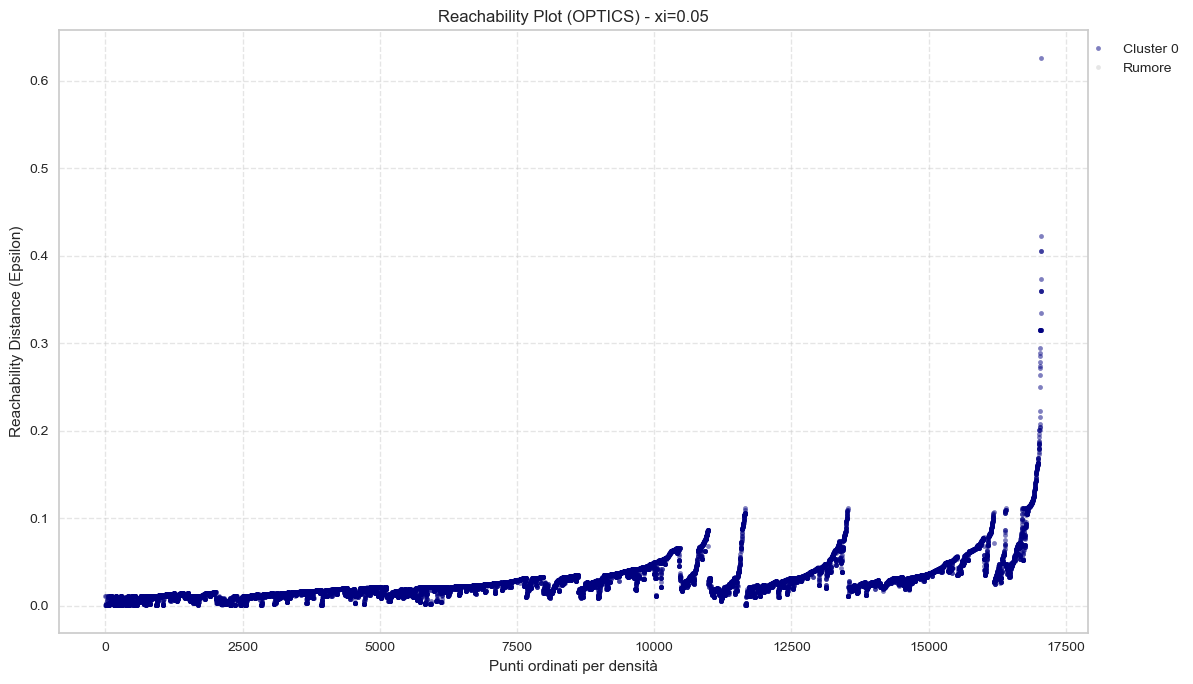

------------------------------
Cluster trovati: 1
Punti di rumore: 0 (0.00%)
------------------------------


In [29]:
# Optics

# 1. Parametri base
D = X_minmax.shape[1]
# È buona norma avere almeno 5 punti come minimo assoluto
MinPts = max(5, 2 * D)

# 2. Esecuzione OPTICS
# Un valore standard è tra 0.01 e 0.1. Lo imposto a 0.05 per bilanciare.
optics = OPTICS(
    min_samples=MinPts,
    xi=0.05,                  # CORRETTO: 0.05 è più sensato di 0.5
    min_cluster_size=0.05,    # Esempio: 1% dei dati totali come dimensione minima cluster
)

optics.fit(X_minmax)

# 3. Preparazione Dati per Reachability Plot
space = np.arange(len(X_minmax))
reachability = optics.reachability_[optics.ordering_]
labels = optics.labels_[optics.ordering_]

# 4. Plot del "Reachability Plot"
#
plt.figure(figsize=(12, 7))

# Logica dinamica per i colori (funziona con QUALSIASI numero di cluster)
unique_labels = np.unique(labels)
clusters_only = unique_labels[unique_labels != -1]
colors = plt.cm.jet(np.linspace(0, 1, len(clusters_only)))

# Plot dei cluster trovati
for klass, color in zip(clusters_only, colors):
    Xk = space[labels == klass]
    Rk = reachability[labels == klass]
    plt.plot(Xk, Rk, color=color, marker='.', linestyle='none',
             alpha=0.5, label=f'Cluster {klass}')

# Plot del rumore (punti neri)
plt.plot(space[labels == -1], reachability[labels == -1],
         'k.', alpha=0.1, label='Rumore')

plt.title(f'Reachability Plot (OPTICS) - xi={optics.xi}')
plt.ylabel('Reachability Distance (Epsilon)')
plt.xlabel('Punti ordinati per densità')
plt.grid(True, linestyle='--', alpha=0.5)
# Legenda fuori dal grafico se ci sono molti cluster
plt.legend(loc='upper right', bbox_to_anchor=(1.1, 1))
plt.tight_layout()
plt.show()

# 5. Preparazione Dati per Visualizzazione 3D
plot_df = pca_df.copy()
# Convertiamo in stringa per categorialità in Plotly, ma teniamo l'ordine corretto
plot_df['cluster'] = optics.labels_.astype(str)

# Statistiche
n_clusters = len(set(optics.labels_)) - (1 if -1 in optics.labels_ else 0)
n_noise = list(optics.labels_).count(-1)
perc_noise = (n_noise / len(plot_df)) * 100

print("-" * 30)
print(f"Cluster trovati: {n_clusters}")
print(f"Punti di rumore: {n_noise} ({perc_noise:.2f}%)")
print("-" * 30)

# 6. Plot 3D
# Ordiniamo le label numericamente per la legenda (altrimenti '10' viene prima di '2')
sorted_labels_int = sorted(list(set(optics.labels_)))
sorted_clusters_str = [str(i) for i in sorted_labels_int]

fig = px.scatter_3d(
    plot_df,
    x='PC1', y='PC2', z='PC3',
    color='cluster',
    title=f"OPTICS Clustering (MinPts={MinPts}, xi={optics.xi})",
    # Rumore in grigio chiaro per non disturbare
    color_discrete_map={'-1': 'lightgrey'},
    category_orders={"cluster": sorted_clusters_str},
    opacity=0.7
)

fig.update_traces(marker=dict(size=3))
fig.show()

In [30]:
# Valutazione clusters
df_sil = pd.DataFrame(columns=["Cluster", "Silhouette"])

# kmeans
labels1 = kmeans.labels_
sil1 = silhouette_score(X_minmax, labels1, random_state=222)
df_sil.loc[len(df_sil)] = {"Cluster": "K-means", "Silhouette": sil1}

# bkmeans
labels2 = bkmeans.labels_
sil2 = silhouette_score(X_minmax, labels2, random_state=222)
df_sil.loc[len(df_sil)] = {"Cluster": "Bisecting K-means", "Silhouette": sil2}

'''# xmeans
clusters_list = xm_model.get_clusters()
labels8 = np.zeros(X_minmax.shape[0], dtype=int)
for cluster_id, idx_list in enumerate(clusters_list):
    for idx in idx_list:
        labels8[idx] = cluster_id

sil8 = silhouette_score(X_minmax, labels8, random_state=222)
df_sil.loc[len(df_sil)] = {"Cluster": "X-means", "Silhouette": sil8}'''

# dbscan
mask = dbscan.labels_ != -1
labels3 = dbscan.labels_[mask]
sil3 = silhouette_score(X_minmax[mask], labels3, random_state=222)
df_sil.loc[len(df_sil)] = {"Cluster": "Dbscan", "Silhouette": sil3}

# Complete
labels4 = fcluster(Z1, t=4, criterion='maxclust')
sil4 = silhouette_score(X_minmax, labels4, random_state=222)
df_sil.loc[len(df_sil)] = {"Cluster": "Hier: Complete", "Silhouette": sil4}

# Single
labels5 = fcluster(Z2, t=4, criterion='maxclust')
sil5 = silhouette_score(X_minmax, labels5, random_state=222)
df_sil.loc[len(df_sil)] = {"Cluster": "Hier: Single", "Silhouette": sil5}

# Average
labels6 = fcluster(Z3, t=4, criterion='maxclust')
sil6 = silhouette_score(X_minmax, labels6, random_state=222)
df_sil.loc[len(df_sil)] = {"Cluster": "Hier: Average", "Silhouette": sil6}

# Ward
labels7 = fcluster(Z4, t=4, criterion='maxclust')
sil7 = silhouette_score(X_minmax, labels7, random_state=222)
df_sil.loc[len(df_sil)] = {"Cluster": "Hier: Ward", "Silhouette": sil7}

print(df_sil)

             Cluster  Silhouette
0            K-means    0.314691
1  Bisecting K-means    0.325282
2             Dbscan   -0.134595
3     Hier: Complete    0.334525
4       Hier: Single    0.544723
5      Hier: Average    0.542197
6         Hier: Ward    0.275813
